<a href="https://colab.research.google.com/github/YasindaAulia/deteksi-api-asap-vgg16/blob/main/deteksi_api_asap_vgg16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deteksi Api dan Asap Berbasis CNN VGG16
Klasifikasi citra ke 3 kelas (**fire**, **smoke**, **neutral**) menggunakan VGG16 + transfer learning.

Dataset: FIRE-SMOKE-DATASET (DeepQuest AI)

## 1. Setup & Unduh Dataset

In [ ]:
# import library
import os, glob, zipfile, urllib.request, random, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image, ImageOps

# seed agar hasil sama setiap dijalankan
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
# parameter
CLASSES = ["fire", "smoke", "neutral"]
IMG, BATCH = 224, 32
EPOCHS1, EPOCHS2 = 15, 15
WEIGHTS = "imagenet"
DATA_DIR = "/content/data"
URL = "https://github.com/DeepQuestAI/Fire-Smoke-Dataset/releases/download/v1/FIRE-SMOKE-DATASET.zip"
# cek GPU
print("GPU:", tf.config.list_physical_devices("GPU"))

# download dataset jika belum ada
if not glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True):
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(URL, "fs.zip")
    zipfile.ZipFile("fs.zip").extractall(DATA_DIR)
# folder untuk menyimpan hasil
for d in ["results", "models", "demo"]:
    os.makedirs(d, exist_ok=True)

# beberapa file .jpg sebenarnya TIFF/PNG/GIF, diubah ke JPEG agar bisa dibaca TensorFlow
n_fix = 0
for p in glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True):
    with Image.open(p) as im:
        if im.format != "JPEG":
            im.convert("RGB").save(p, "JPEG", quality=95); n_fix += 1
print("File dikonversi ke JPEG:", n_fix)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
File dikonversi ke JPEG: 159


## 2. Eksplorasi Data (EDA)

Total citra: 3000
label
fire       1000
neutral    1000
smoke      1000
Name: count, dtype: int64


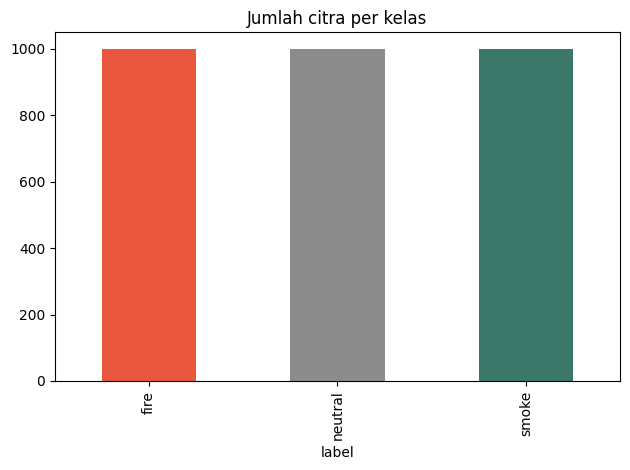

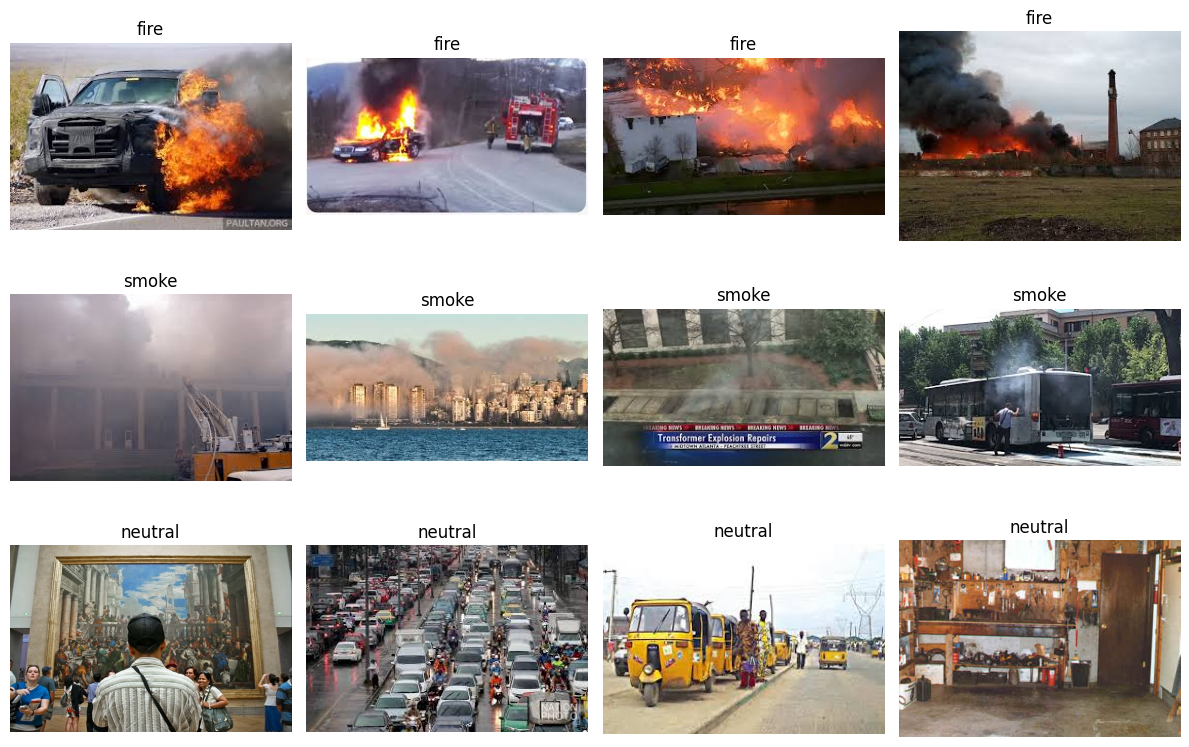

In [ ]:
# ambil path gambar, label dari nama folder
rows = []
for p in glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True):
    c = os.path.basename(os.path.dirname(p)).lower()
    if c in CLASSES:
        rows.append((p, CLASSES.index(c)))
df = pd.DataFrame(rows, columns=["path", "label"])
print("Total citra:", len(df)); print(df["label"].map(lambda i: CLASSES[i]).value_counts())

# jumlah gambar per kelas
df["label"].map(lambda i: CLASSES[i]).value_counts().plot(kind="bar", color=["#E9573F", "#8C8C8C", "#3B786A"], title="Jumlah citra per kelas")
plt.tight_layout(); plt.savefig("results/distribusi_kelas.png", dpi=150); plt.show()

# contoh 4 gambar tiap kelas
fig, ax = plt.subplots(3, 4, figsize=(12, 8))
for i, c in enumerate(CLASSES):
    for j, p in enumerate(df[df.label == i].sample(4, random_state=SEED).path):
        ax[i, j].imshow(plt.imread(p)); ax[i, j].axis("off"); ax[i, j].set_title(c)
plt.tight_layout(); plt.savefig("results/contoh_kelas.png", dpi=150); plt.show()

## 3. Split Data, Pipeline & Augmentasi

In [ ]:
# split data 70% train, 15% validasi, 15% test
tr, tmp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=SEED)
split_tab = pd.DataFrame({n: d.label.map(lambda i: CLASSES[i]).value_counts() for n, d in [("train", tr), ("val", va), ("test", te)]})
print(split_tab); split_tab.to_csv("results/tabel_split.csv")

# baca gambar, resize 224x224, lalu preprocessing VGG16
def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))
    # RGB ke BGR lalu dikurangi mean ImageNet
    img = img[..., ::-1] - tf.constant([103.939, 116.779, 123.68])
    return img, y

# dataset per batch
def make_ds(d, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values)).map(load, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle: ds = ds.shuffle(len(d), seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

ds_tr, ds_va, ds_te = make_ds(tr, True), make_ds(va), make_ds(te)

# augmentasi: flip, rotasi, zoom, brightness
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2, value_range=(-130, 140)),
], name="augmentasi")

         train  val  test
label                    
fire       700  150   150
neutral    700  150   150
smoke      700  150   150


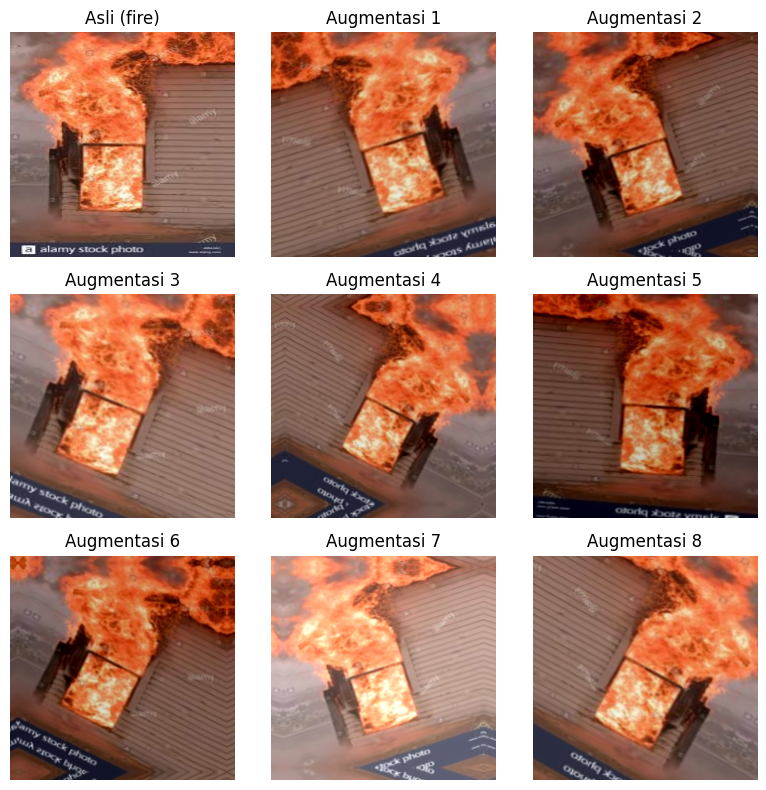

In [ ]:
# kembalikan ke RGB biasa untuk ditampilkan
MEAN = tf.constant([103.939, 116.779, 123.68])
def to_rgb(x):
    return np.clip((x + MEAN).numpy()[..., ::-1] / 255.0, 0, 1)

# contoh augmentasi dari 1 gambar fire
p0 = tr[tr.label == 0].path.values[0]
x0, _ = load(p0, 0)
fig, ax = plt.subplots(3, 3, figsize=(8, 8)); ax = ax.ravel()
ax[0].imshow(to_rgb(x0)); ax[0].set_title("Asli (fire)")
for i in range(1, 9):
    ax[i].imshow(to_rgb(augment(x0[None], training=True)[0])); ax[i].set_title(f"Augmentasi {i}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("results/augmentasi.png", dpi=150); plt.show()

## 4. Model VGG16 + Transfer Learning

In [ ]:
# model: VGG16 + layer klasifikasi baru
def build_model(use_aug=True):
    base = keras.applications.VGG16(include_top=False, weights=WEIGHTS, input_shape=(IMG, IMG, 3))
    # bobot VGG16 dibekukan
    base.trainable = False
    inp = keras.Input((IMG, IMG, 3))
    x = augment(inp) if use_aug else inp
    x = base(x, training=False)
    # layer klasifikasi
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inp, out), base

# training 2 tahap
def train(use_aug=True, finetune=True, tag="C"):
    model, base = build_model(use_aug)
    ck = f"models/model_{tag}.keras"
    # early stopping dan simpan model terbaik
    cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
          keras.callbacks.ModelCheckpoint(ck, monitor="val_accuracy", save_best_only=True)]
    # tahap 1: latih layer klasifikasi saja
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS1, callbacks=cb, verbose=2)
    hist = dict(h1.history); n1 = len(h1.history["loss"])
    # tahap 2: fine-tuning block5 dengan learning rate kecil
    if finetune:
        base.trainable = True
        for l in base.layers: l.trainable = l.name.startswith("block5")
        model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        h2 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS2, callbacks=cb, verbose=2)
        hist = {k: hist[k] + h2.history[k] for k in hist}
    # pakai model dengan val accuracy terbaik
    model = keras.models.load_model(ck)
    return model, hist, n1

# ringkasan arsitektur model
m_summary, _ = build_model(use_aug=True)
m_summary.summary(show_trainable=True)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_5 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentasi (Sequential)     │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ vgg16 (Functional)          │ (None, 7, 7, 512)     │ 14,714,688 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d_1  │ (None, 512)           │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_2 (Dense)             │ (None, 256)           │    131,328 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_1 (Dropout)         │ (None, 256)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_3 (Dense)             │ (None, 3)             │        771 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 14,846,787 (56.64 MB)

 Trainable params: 132,099 (516.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 5. Eksperimen Skenario A–C


========== Skenario A ==========
Epoch 1/15
66/66 - 65s - 987ms/step - accuracy: 0.8057 - loss: 0.9866 - val_accuracy: 0.9244 - val_loss: 0.2751
Epoch 2/15
66/66 - 41s - 616ms/step - accuracy: 0.9195 - loss: 0.2537 - val_accuracy: 0.9400 - val_loss: 0.2175
Epoch 3/15
66/66 - 23s - 354ms/step - accuracy: 0.9395 - loss: 0.1895 - val_accuracy: 0.9422 - val_loss: 0.1788
Epoch 4/15
66/66 - 22s - 338ms/step - accuracy: 0.9605 - loss: 0.1163 - val_accuracy: 0.9489 - val_loss: 0.1820
Epoch 5/15
66/66 - 22s - 329ms/step - accuracy: 0.9633 - loss: 0.0963 - val_accuracy: 0.9467 - val_loss: 0.2026
Epoch 6/15
66/66 - 42s - 636ms/step - accuracy: 0.9681 - loss: 0.0901 - val_accuracy: 0.9556 - val_loss: 0.1682
Epoch 7/15
66/66 - 22s - 335ms/step - accuracy: 0.9805 - loss: 0.0595 - val_accuracy: 0.9400 - val_loss: 0.2032
Epoch 8/15
66/66 - 42s - 631ms/step - accuracy: 0.9824 - loss: 0.0467 - val_accuracy: 0.9578 - val_loss: 0.1841
Epoch 9/15
66/66 - 22s - 335ms/step - accuracy: 0.9843 - loss: 0.0489 

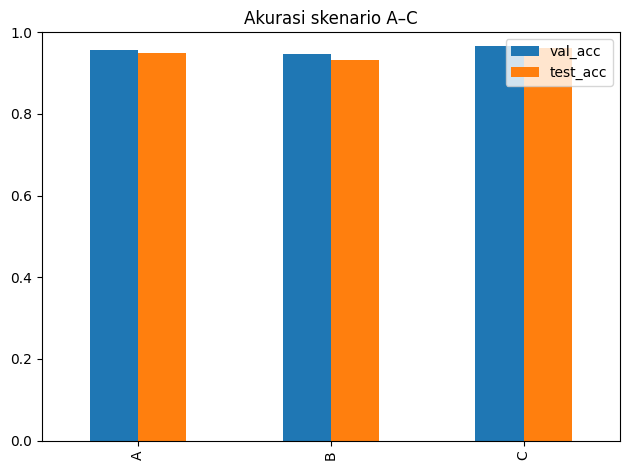

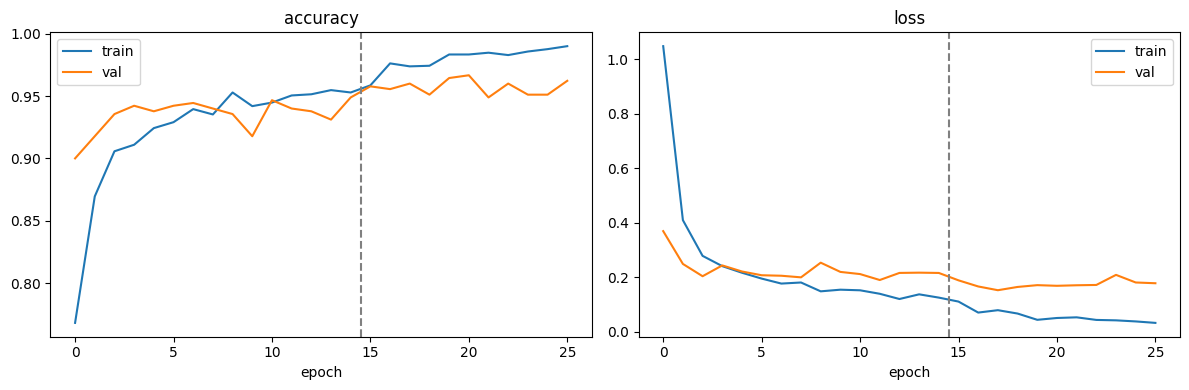

In [ ]:
# A: tanpa augmentasi & fine-tuning, B: + augmentasi, C: + augmentasi & fine-tuning
hasil = {}
for tag, aug, ft in [("A", False, False), ("B", True, False), ("C", True, True)]:
    print(f"\n========== Skenario {tag} ==========")
    t0 = time.time()
    m, hist, n1 = train(aug, ft, tag)
    menit = (time.time() - t0) / 60
    hasil[tag] = {"augmentasi": aug, "fine_tuning": ft, "epoch": len(hist["loss"]), "waktu_menit": round(menit, 1),
                  "val_acc": max(hist["val_accuracy"]), "test_acc": m.evaluate(ds_te, verbose=0)[1]}
    if tag == "C": model, hist_C, n1_C = m, hist, n1

# tabel dan grafik perbandingan akurasi
tab = pd.DataFrame(hasil).T; print(tab); tab.to_csv("results/tabel_eksperimen.csv")
tab[["val_acc", "test_acc"]].astype(float).plot(kind="bar", title="Akurasi skenario A–C"); plt.ylim(0, 1)
plt.tight_layout(); plt.savefig("results/grafik_eksperimen.png", dpi=150); plt.show()

# kurva training model C (garis putus-putus = mulai fine-tuning)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, k in enumerate(["accuracy", "loss"]):
    ax[i].plot(hist_C[k], label="train"); ax[i].plot(hist_C["val_" + k], label="val")
    ax[i].axvline(n1_C - 0.5, ls="--", c="gray"); ax[i].set_title(k); ax[i].set_xlabel("epoch"); ax[i].legend()
plt.tight_layout(); plt.savefig("results/kurva_training.png", dpi=150); plt.show()

## 6. Evaluasi Model Final

Test accuracy: 0.9622 | Test loss: 0.1861

15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 172ms/step
              precision    recall  f1-score   support

        fire     0.9536    0.9600    0.9568       150
       smoke     0.9726    0.9467    0.9595       150
     neutral     0.9608    0.9800    0.9703       150

    accuracy                         0.9622       450
   macro avg     0.9623    0.9622    0.9622       450
weighted avg     0.9623    0.9622    0.9622       450

Recall fire: 0.9600


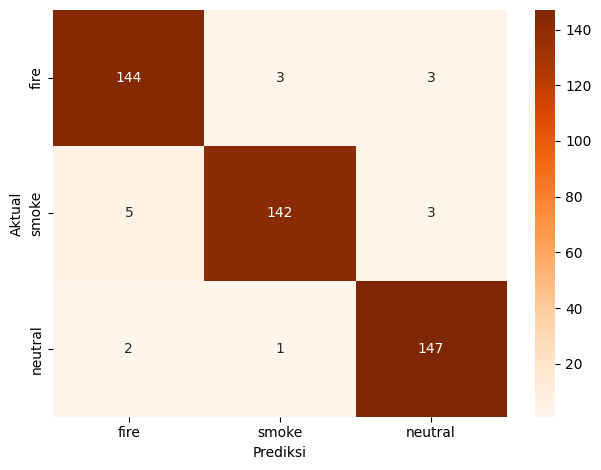

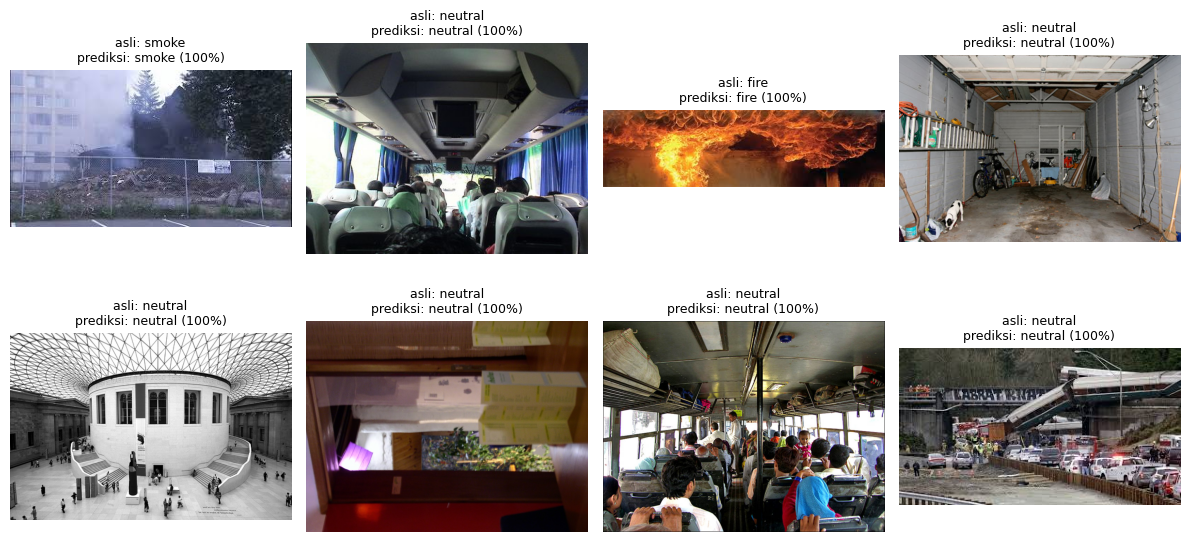

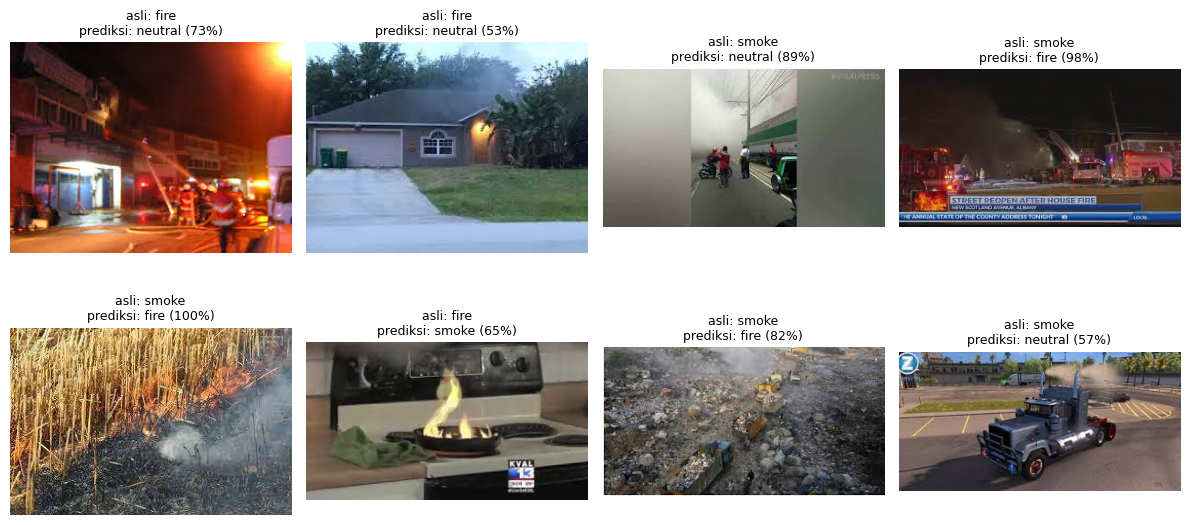

In [ ]:
# akurasi pada data test
test_loss, test_acc = model.evaluate(ds_te, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}\n")

# precision, recall, f1-score tiap kelas
y_true = te.label.values
prob = model.predict(ds_te); y_pred = prob.argmax(1)
print(classification_report(y_true, y_pred, labels=range(3), target_names=CLASSES, digits=4, zero_division=0))
rep = classification_report(y_true, y_pred, labels=range(3), target_names=CLASSES, output_dict=True, zero_division=0)
pd.DataFrame(rep).T.to_csv("results/classification_report.csv")
print(f"Recall fire: {rep['fire']['recall']:.4f}")

# confusion matrix
sns.heatmap(confusion_matrix(y_true, y_pred, labels=range(3)), annot=True, fmt="d", cmap="Oranges", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.tight_layout(); plt.savefig("results/confusion_matrix.png", dpi=150); plt.show()

# contoh prediksi benar dan salah
for name, mask in [("benar", y_pred == y_true), ("salah", y_pred != y_true)]:
    idx = np.where(mask)[0][:8]
    if len(idx) == 0: continue
    fig, ax = plt.subplots(2, 4, figsize=(12, 6))
    for a in ax.ravel(): a.axis("off")
    for a, i in zip(ax.ravel(), idx):
        a.imshow(plt.imread(te.path.values[i]))
        a.set_title(f"asli: {CLASSES[y_true[i]]}\nprediksi: {CLASSES[y_pred[i]]} ({prob[i].max()*100:.0f}%)", fontsize=9)
    plt.tight_layout(); plt.savefig(f"results/prediksi_{name}.png", dpi=150); plt.show()

## 7. Demo Prediksi

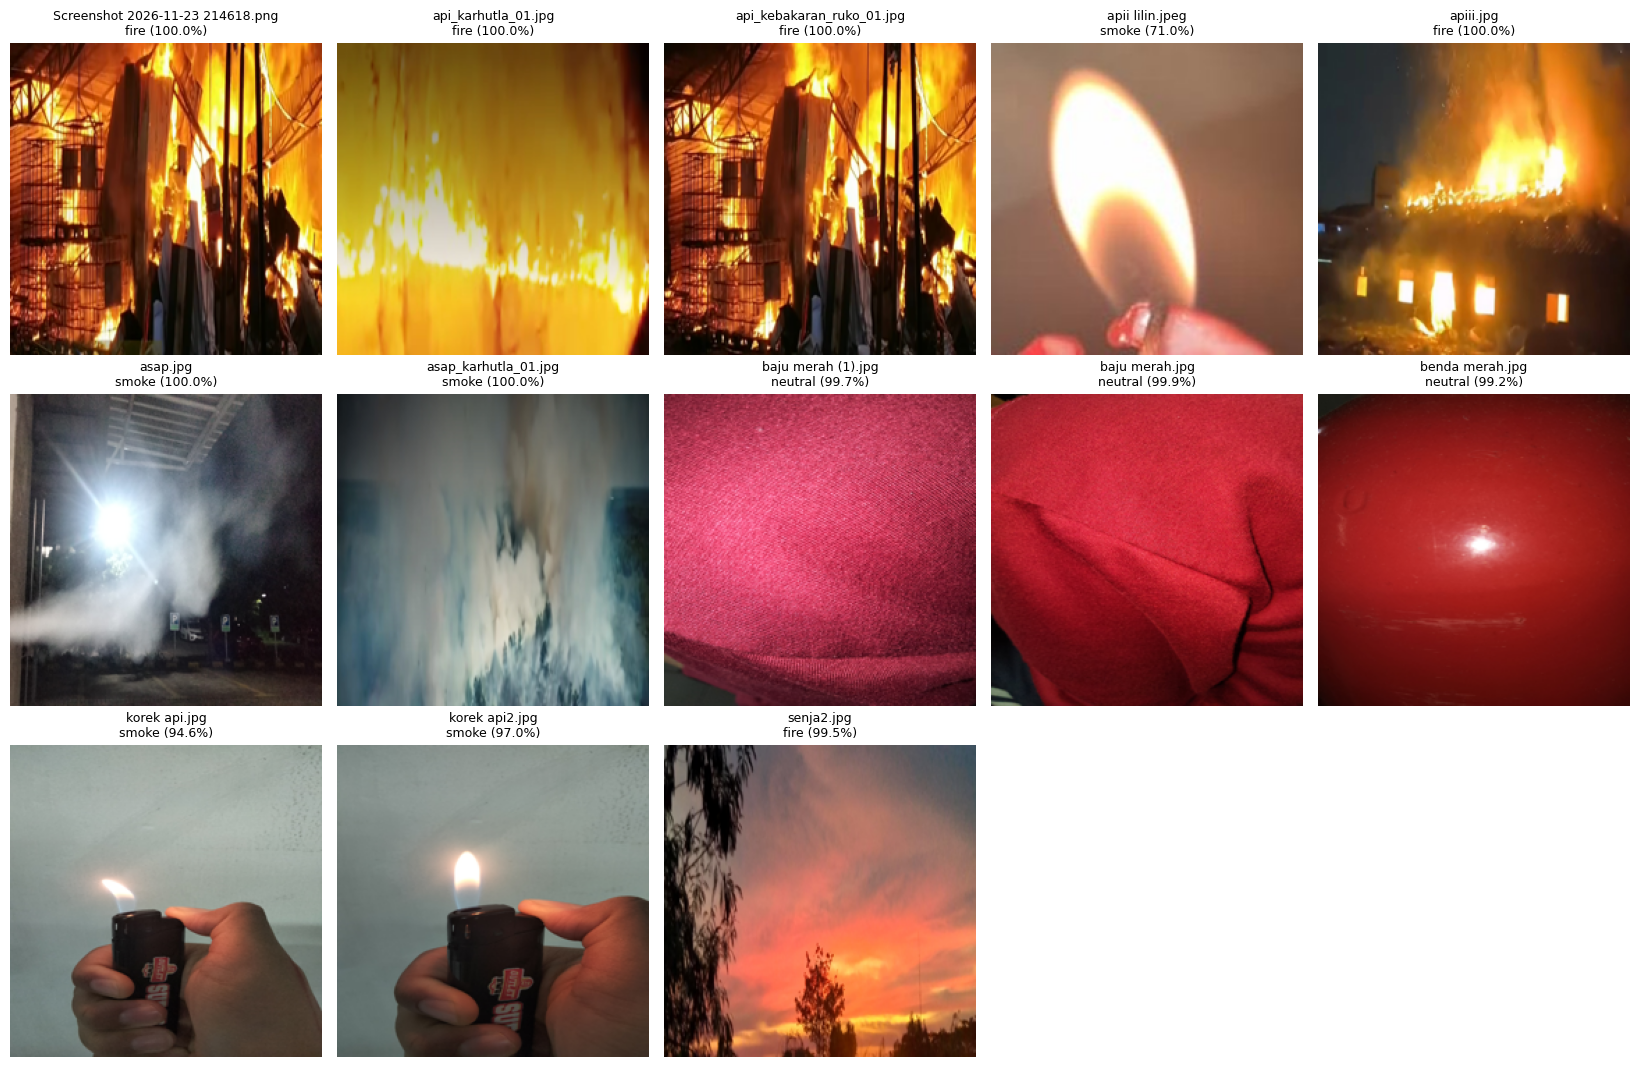

,file,prediksi,probabilitas
0,Screenshot 2026-11-23 214618.png,fire,1.0000
1,api_karhutla_01.jpg,fire,1.0000
2,api_kebakaran_ruko_01.jpg,fire,1.0000
3,apii lilin.jpeg,smoke,0.7101
4,apiii.jpg,fire,1.0000
5,asap.jpg,smoke,1.0000
6,asap_karhutla_01.jpg,smoke,1.0000
7,baju merah (1).jpg,neutral,0.9974
8,baju merah.jpg,neutral,0.9987
9,benda merah.jpg,neutral,0.9923


In [ ]:
# preprocessing foto demo, sama seperti data training
def load_demo(path):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB").resize((IMG, IMG))
    rgb = np.array(im, dtype="float32")
    return rgb, rgb[..., ::-1] - np.array([103.939, 116.779, 123.68], dtype="float32")

# prediksi semua foto di folder demo/
files = sorted(f for f in glob.glob("demo/*") if f.lower().endswith((".jpg", ".jpeg", ".png")))
if not files:
    print("Folder demo/ masih kosong. Upload foto demo ke folder demo/ lalu jalankan ulang sel ini.")
else:
    pairs = [load_demo(f) for f in files]
    prob_demo = model.predict(np.stack([x for _, x in pairs]), verbose=0)
    cols = 5; rows_ = int(np.ceil(len(files) / cols))
    fig, ax = plt.subplots(rows_, cols, figsize=(3.3 * cols, 3.6 * rows_), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, f, (rgb, _), p in zip(ax.ravel(), files, pairs, prob_demo):
        a.imshow(rgb.astype("uint8"))
        a.set_title(f"{os.path.basename(f)}\n{CLASSES[p.argmax()]} ({p.max()*100:.1f}%)", fontsize=9)
    plt.tight_layout(); plt.savefig("results/demo.png", dpi=150); plt.show()
    display(pd.DataFrame({"file": [os.path.basename(f) for f in files],
                          "prediksi": [CLASSES[i] for i in prob_demo.argmax(1)],
                          "probabilitas": prob_demo.max(1).round(4)}))

## 8. Simpan & Muat dari Google Drive
### Simpan

In [ ]:
# simpan model dan hasil ke Google Drive
from google.colab import drive
import shutil
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/deteksi_api_asap"
for d in ["models", "results", "demo"]:
    shutil.copytree(d, f"{DRIVE_DIR}/{d}", dirs_exist_ok=True)
print("Tersimpan di Google Drive:", DRIVE_DIR)
for d in ["models", "results", "demo"]:
    print(f"  {d}/:", sorted(os.listdir(f"{DRIVE_DIR}/{d}")))

Mounted at /content/drive
Tersimpan di Google Drive: /content/drive/MyDrive/deteksi_api_asap
  models/: ['model_A.keras', 'model_B.keras', 'model_C.keras']
  results/: ['augmentasi.png', 'classification_report.csv', 'confusion_matrix.png', 'contoh_kelas.png', 'distribusi_kelas.png', 'grafik_eksperimen.png', 'kurva_training.png', 'prediksi_benar.png', 'prediksi_salah.png', 'tabel_eksperimen.csv', 'tabel_split.csv']
  demo/: []


### Muat

In [ ]:
# ambil kembali dari Drive tanpa training ulang
from google.colab import drive
import shutil
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/deteksi_api_asap"
for d in ["models", "results", "demo"]:
    if os.path.exists(f"{DRIVE_DIR}/{d}"):
        shutil.copytree(f"{DRIVE_DIR}/{d}", d, dirs_exist_ok=True)
model = keras.models.load_model("models/model_C.keras")
print("Model C dimuat dari Drive. Foto di demo/:", sorted(os.listdir("demo")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model C dimuat dari Drive. Foto di demo/: []
